# Grain or silage? Corn harvest type from public data

Three models from team Kernel's entry to **Hack the Harvest 2026** (UC Davis × USDA NASS). Background, data sources and
a detailed description of each model are in `README.md`. This notebook runs them and explains how to read their output.

| # | Model | Answers | Unit |
|---|---|---|---|
| 1 | **Caveman rule** | Was **this field** chopped for silage or harvested for grain? | one field |
| 2 | **A-G9** | How many acres of corn are harvested **for grain**? | state and US acres |
| 3 | **B-S6** | How many acres of corn are harvested **for silage**? | state and US acres |

**How to run:** `pip install -r requirements.txt`, then *Run All*. Everything reads the files in `data/` and runs offline
in about a minute. Only the optional section (classify a new field) downloads satellite pictures.

**How the acreage models are scored:** each year is forecast as of **15 November**, using only data that was public by
that date, then compared with NASS's final survey acres (published the following January).

* **State error** = sum over states of |forecast − NASS final| ÷ sum of NASS final acres. 1.7% means that, summed over
  all states, 1.7% of the acres were put in the wrong state or missed.
* **US error** = (US forecast − US final) ÷ US final. Positive = too high.
* **Same as last year** = copy each state's final acres from the previous year: the baseline every model must beat.
* 2017–2024 were used while the methods were developed. **2025 was scored once, after they were fixed**; it is also the
  year the organizers scored entries against.

In [1]:
import warnings
from datetime import date
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=RuntimeWarning)   # log(0) for states with no silage in early years
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
DATA = Path("data")


def nass_item(file, short_desc):
    # One NASS Quick Stats item as tidy rows (state-level survey totals): year, state, period, value.
    raw = pd.read_csv(DATA / "nass" / file, dtype=str, keep_default_na=False)
    rows = raw[(raw["agg_level_desc"] == "STATE") & (raw["source_desc"] == "SURVEY")
               & (raw["domain_desc"] == "TOTAL") & (raw["short_desc"] == short_desc)]
    out = pd.DataFrame({"year": rows["year"].astype(int), "state": rows["state_name"],
                        "period": rows["reference_period_desc"],
                        "value": pd.to_numeric(rows["Value"].str.replace(",", ""), errors="coerce")})
    return out.dropna(subset=["value"]).drop_duplicates(["year", "state", "period"])


def wide(table, periods):
    # Year x state table, taking the first of `periods` that exists for each state-year.
    out = pd.DataFrame()
    for p in periods:
        out = out.combine_first(table[table["period"] == p].pivot(index="year", columns="state", values="value"))
    return out


GRAIN = nass_item("corn_grain_harvested_acres_state_2000_2026.csv", "CORN, GRAIN - ACRES HARVESTED")
SILAGE = nass_item("corn_silage_harvested_acres_state_2000_2026.csv", "CORN, SILAGE - ACRES HARVESTED")
YIELD = nass_item("corn_grain_yield_state_2000_2026.csv", "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE")

# NASS final acres and yields (2026 values in the files are in-season forecasts, not finals)
GRAIN_FINAL = wide(GRAIN[GRAIN["year"] <= 2025], ["YEAR"])
SILAGE_FINAL = wide(SILAGE[SILAGE["year"] <= 2025], ["YEAR"])
YIELD_FINAL = wide(YIELD[YIELD["year"] <= 2025], ["YEAR"])
# NASS's latest in-season yield forecast out by 15 November (November report, else October, September, August)
YIELD_NOV = wide(YIELD, ["YEAR - NOV FORECAST", "YEAR - OCT FORECAST", "YEAR - SEP FORECAST", "YEAR - AUG FORECAST"])


def score(pred_by_year, final):
    # State error and US error per year, on the states with a NASS final this year and last year.
    rows = []
    for t, p in pred_by_year.items():
        states = final.loc[t].dropna().index.intersection(final.loc[t - 1].dropna().index).intersection(p.dropna().index)
        actual, pred = final.loc[t, states], p[states]
        rows.append({"year": t, "states": len(states),
                     "state_error_%": 100 * (pred - actual).abs().sum() / actual.sum(),
                     "us_error_%": 100 * (pred.sum() - actual.sum()) / actual.sum()})
    return pd.DataFrame(rows).set_index("year")


def same_as_last_year(final, years):
    return {t: final.loc[t - 1] for t in years}


def summary(model_scores, baseline_scores):
    rows = {}
    for name, s in [("model", model_scores), ("same as last year", baseline_scores)]:
        rows[(name, "2017-2024 state error %")] = s.loc[2017:2024, "state_error_%"].mean()
        rows[(name, "2017-2024 |US error| %")] = s.loc[2017:2024, "us_error_%"].abs().mean()
        rows[(name, "2025 state error %")] = s.loc[2025, "state_error_%"]
        rows[(name, "2025 US error %")] = s.loc[2025, "us_error_%"]
    return pd.Series(rows).unstack(0).round(2)


def us_range(pred_us, scores_by_year):
    # Rough 80% range for a US total: the 10th-90th percentile of past US misses, applied to this forecast.
    misses = scores_by_year["us_error_%"] / 100
    lo, hi = np.quantile(misses, [0.1, 0.9])
    return pred_us * (1 + lo), pred_us * (1 + hi)

## 1. Field by field: the caveman rule

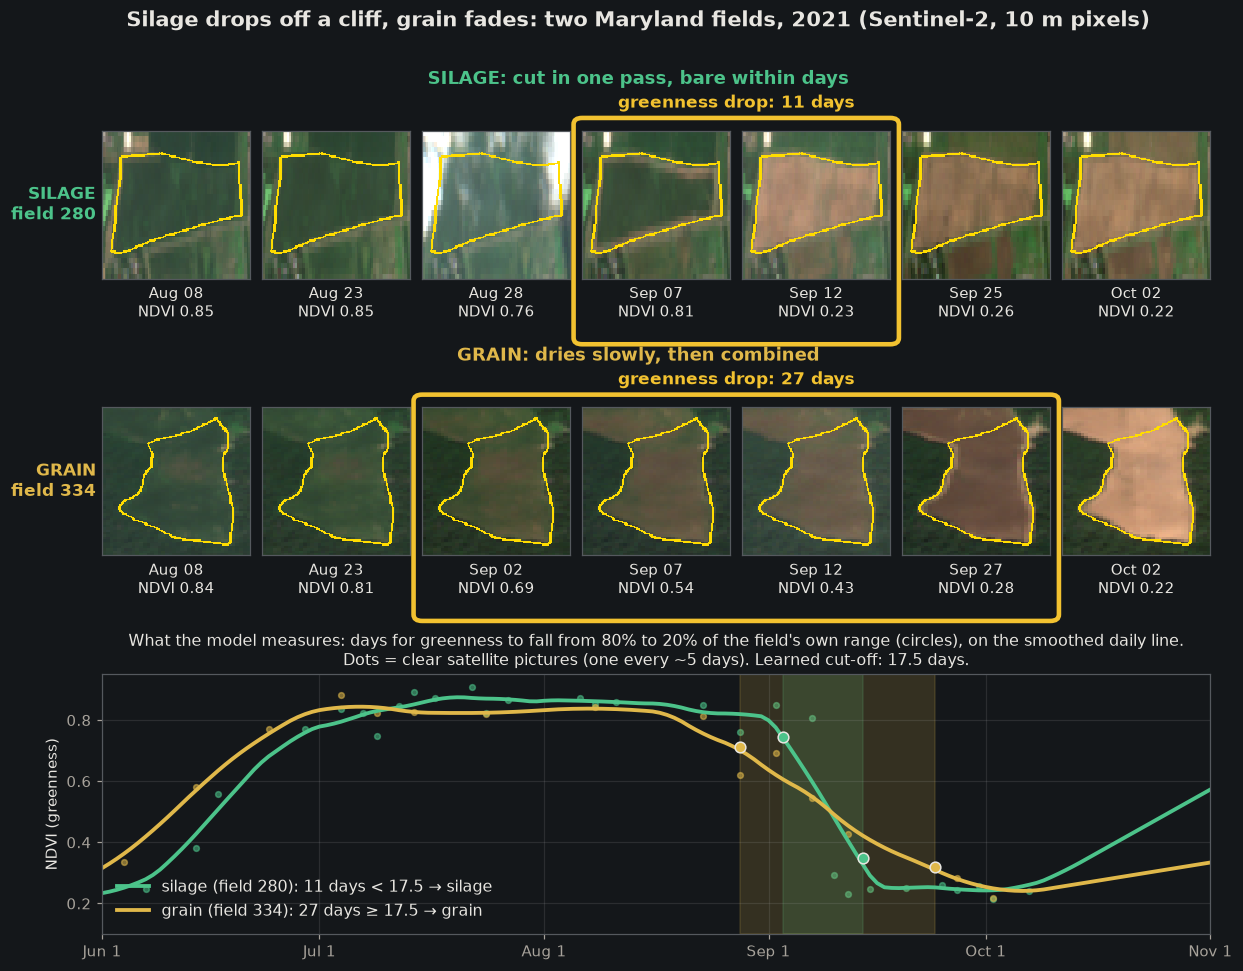

The acreage models answer "how many acres". The organizers' field question is different: was **this** field
chopped for silage or harvested for grain? What worked best was a simple rule, derived by hand:

* **Rule 1.** Corn fields grown for **silage** lose their greenness (NDVI) in **under 17.5 days**. The field is
  cut in one go, and the whole plant (stalks, leaves and ears) is harvested, because silage uses the entire plant.
* Fields of **grain** corn take **17.5 days or more** to lose their greenness. The corn ripens slowly, and from
  the satellite the field gradually turns from green to yellow.

"Losing greenness" is measured as the number of days NDVI takes to fall from 80% to 20% of the field's own seasonal
range, on a daily line built from every clear Sentinel-2 picture (one every ~5 days, 10 m pixels).

Only **one weight** is actually "trained":

* **X** = the longest a silage field can take to lose its greenness. A field that takes longer is grain corn.

Learned on 801 fields in **Quebec, Canada** (farm declarations, 2023), X comes out at **17.5 days**. Applied unchanged
to USDA's **44 Maryland field-years** (Beltsville research farm, 2021–2023; never used for learning), it gets
**42 of 44 right: 95.5% accuracy**, against 72.7% for always guessing "grain". Learned on Maryland instead, X is
also 17.5 days.

**Rule 2 (optional), variable Z: was something planted for the winter?** After an early silage cut, farmers
often sow a cover crop, so the field is green again in November–December (NDVI > 0.65). This check is only
applied when both of these hold:

1. **Rule 1 is unsure.** The field took between 17.5 and 20.5 days, just over the line. Far from the line,
   rule 1 alone decides: a winter crop is common after grain too, because grain is far more common.
2. **The field's county has winters mild enough for a green crop.** That is an average Nov–Dec temperature of at least
   4 °C, from `data/regions/winter_vegetation.csv`. The field's coordinates are matched to its county
   (or to Quebec) automatically. In colder regions the check is switched off, because snow hides any crop.

If both hold and the field is green in winter, the call flips to silage. With rule 2 applied this way, the 2
Maryland misses stay misses (they are not borderline), and no grain field is wrongly flipped. Applied to *every* field
instead, rule 2 would score 44/44 on Maryland, but that version was tuned by hand on the same 44 fields and is not
used.

**How to read the output:** a confusion matrix per test (rows = truth, columns = call), and a per-field table where
`drop_days` is X for that field, `winter_ndvi` is Z and `rule` says which rule made the call.

In [2]:
MIN_CLEAR = 0.4                 # use a satellite picture only if >= 40% of the field is cloud-free
SMOOTH_DAYS = 15                # smooth the daily greenness line over 15 days
SPRING = (90, 170)              # the pre-season low is looked for between early April and mid-June
DROP_FROM, DROP_TO = 0.8, 0.2   # the drop clock runs from 80% down to 20% of the field's greenness range
WINTER_DAYS = (300, 355)        # late October to late December
WINTER_GREEN = 0.65             # rule 2: NDVI above this in Nov-Dec = a crop growing after harvest
BORDER_BAND = 3.0               # rule 2 only for fields 0-3 days slower than the cut-off


def greenness_line(series):
    # Daily NDVI line of one field-year: clear pictures only, gaps filled linearly, 15-day rolling mean.
    s = series[series["valid_frac"] >= MIN_CLEAR].dropna(subset=["ndvi"])
    if len(s) < 5:
        return pd.Series(dtype=float)
    s = s.groupby(pd.to_datetime(s["date"]).dt.day_of_year)["ndvi"].median()
    s = s.reindex(np.arange(s.index.min(), s.index.max() + 1)).interpolate()
    return s.rolling(SMOOTH_DAYS, center=True, min_periods=1).mean()


def field_features(series):
    # X = drop_days (rule 1) and Z = winter_ndvi (rule 2) for one field-year.
    out = {"drop_days": np.nan, "winter_ndvi": np.nan}
    day = pd.to_datetime(series["date"]).dt.day_of_year
    winter = series[(series["valid_frac"] >= MIN_CLEAR) & day.between(*WINTER_DAYS)]["ndvi"]
    if len(winter):
        out["winter_ndvi"] = float(winter.median())
    line = greenness_line(series)
    if line.empty:
        return out
    peak_day = int(line.idxmax())
    spring = line.loc[SPRING[0]:min(SPRING[1], peak_day)]
    if spring.empty:
        return out
    low = spring.min()
    span = line.loc[peak_day] - low
    after = line.loc[peak_day:]
    start, end = after[after <= low + DROP_FROM * span], after[after <= low + DROP_TO * span]
    if len(start) and len(end):
        out["drop_days"] = int(end.index[0] - start.index[0])
    return out


def features(ndvi, fields):
    groups = dict(tuple(ndvi.groupby(["field_id", "year"])))
    rows = [{"field_id": f, "year": y, **(field_features(groups[(f, y)]) if (f, y) in groups else {})}
            for f, y in zip(fields["field_id"], fields["year"])]
    return fields.merge(pd.DataFrame(rows), on=["field_id", "year"])


def learn_cutoff(drop_days, is_silage):
    # The only learned weight: try every cut-off between observed values, keep the best silage F1.
    x = np.nan_to_num(np.asarray(drop_days, float), nan=np.inf)
    y = np.asarray(is_silage, bool)
    values = np.unique(x[np.isfinite(x)])
    candidates = (values[:-1] + values[1:]) / 2

    def f1(c):
        p = x < c
        tp, fp, fn = (p & y).sum(), (p & ~y).sum(), (~p & y).sum()
        return 2 * tp / (2 * tp + fp + fn)

    scores = np.array([f1(c) for c in candidates])
    return float(np.median(candidates[scores == scores.max()]))


REGIONS = gpd.read_parquet(DATA / "regions" / "regions.parquet")          # US counties + Quebec outlines
WINTER = pd.read_csv(DATA / "regions" / "winter_vegetation.csv", dtype={"region_id": str})


def region_of(geometries, crs):
    # County (US) or province (Quebec) of each field's centre, and whether its winters allow a green crop.
    centres = gpd.GeoSeries(geometries, crs=crs).to_crs(3857).centroid.to_crs(4326)
    hit = gpd.sjoin(gpd.GeoDataFrame(geometry=centres), REGIONS[["region_id", "geometry"]], how="left", predicate="within")
    hit = hit[~hit.index.duplicated()]
    out = hit[["region_id"]].merge(WINTER[["region_id", "name", "state", "winter_vegetation"]], on="region_id", how="left")
    out["winter_vegetation"] = out["winter_vegetation"].astype("boolean").fillna(False).astype(bool)
    return out


def predict(feat, cutoff, band=BORDER_BAND):
    x = feat["drop_days"].to_numpy(float)
    rule1 = np.nan_to_num(x, nan=np.inf) < cutoff
    borderline = (x >= cutoff) & (x < cutoff + band)
    rule2 = borderline & feat["winter_vegetation"].to_numpy(bool) & (feat["winter_ndvi"].to_numpy(float) > WINTER_GREEN)
    call = (rule1 | rule2).astype(int)
    rule = np.select([rule1, rule2, np.isnan(x)], ["1: fast drop", "2: borderline + winter green", "no measurable drop -> grain"],
                     "1: slow drop -> grain")
    return call, rule


def confusion(y, p, title):
    y, p = np.asarray(y, int), np.asarray(p, int)
    m = pd.DataFrame([[((y == 0) & (p == 0)).sum(), ((y == 0) & (p == 1)).sum()],
                      [((y == 1) & (p == 0)).sum(), ((y == 1) & (p == 1)).sum()]],
                     index=["truly grain", "truly silage"], columns=["called grain", "called silage"])
    tp, fp, fn = m.iloc[1, 1], m.iloc[0, 1], m.iloc[1, 0]
    print(f"{title}: {np.trace(m.values)}/{len(y)} correct = {np.trace(m.values) / len(y):.1%} | "
          f"silage precision {tp / max(tp + fp, 1):.2f}, recall {tp / max(tp + fn, 1):.2f} | "
          f"always-grain baseline {np.mean(y == 0):.1%}")
    return m

In [3]:
# USDA's Maryland labels (the organizers' evaluation data) and their NDVI series
barc = gpd.read_file(DATA / "BARC_Corn.2021-2023.gpkg")
labels = barc.melt(id_vars=["OBJECTID", "geometry"], value_vars=["Corn_2021", "Corn_2022", "Corn_2023"], value_name="label")
labels = labels[labels["label"].isin(["Grain", "Silage"])].reset_index(drop=True)
maryland = pd.concat([pd.DataFrame({"field_id": "barc_" + labels["OBJECTID"].astype(str),
                                    "year": labels["variable"].str[-4:].astype(int),
                                    "silage": (labels["label"] == "Silage").astype(int)}),
                      region_of(labels.geometry.values, barc.crs)], axis=1)
ndvi_md = pd.read_parquet(DATA / "satellite" / "barc_ndvi_2021_2023.parquet")
ndvi_md["year"] = pd.to_datetime(ndvi_md["date"]).dt.year
maryland = features(ndvi_md, maryland)

# Quebec farm declarations (801 corn parcels in three areas, 2023) and their NDVI series
qc = gpd.read_parquet(DATA / "labels" / "quebec_corn_2023.parquet")
quebec = pd.concat([pd.DataFrame({"field_id": qc["field_id"], "year": qc["year"], "silage": (qc["label"] == "silage").astype(int)}),
                    region_of(qc.geometry.values, qc.crs)], axis=1)
ndvi_qc = pd.read_parquet(DATA / "satellite" / "quebec_ndvi_2023.parquet")
ndvi_qc["year"] = pd.to_datetime(ndvi_qc["date"]).dt.year
quebec = features(ndvi_qc, quebec)

print("Maryland fields:", len(maryland), "| regions:", maryland["name"].value_counts().to_dict(),
      "| winter vegetation:", maryland["winter_vegetation"].all())
print("Quebec fields:", len(quebec), "| regions:", quebec["name"].value_counts().to_dict(),
      "| winter vegetation:", quebec["winter_vegetation"].any())

Maryland fields: 44 | regions: {"Prince George's County": 44} | winter vegetation: True
Quebec fields: 801 | regions: {'Quebec': 801} | winter vegetation: False


In [4]:
# Headline test: learn X on Quebec only, apply unchanged to Maryland
x_quebec = learn_cutoff(quebec["drop_days"], quebec["silage"])
x_maryland = learn_cutoff(maryland["drop_days"], maryland["silage"])
print(f"X learned on Quebec: {x_quebec} days | X learned on Maryland: {x_maryland} days\n")

maryland["call"], maryland["rule"] = predict(maryland, x_quebec)
confusion(maryland["silage"], maryland["call"], "Learned in Quebec -> tested on Maryland")

X learned on Quebec: 17.5 days | X learned on Maryland: 17.5 days

Learned in Quebec -> tested on Maryland: 42/44 correct = 95.5% | silage precision 1.00, recall 0.83 | always-grain baseline 72.7%


,called grain,called silage
truly grain,32,0
truly silage,2,10


In [5]:
# Other directions, for completeness
pred = []
for y in (2021, 2022, 2023):                         # Maryland only: learn on two years, test on the third
    train, test = maryland[maryland["year"] != y], maryland[maryland["year"] == y]
    pred.append(pd.Series(predict(test, learn_cutoff(train["drop_days"], train["silage"]))[0], index=test.index))
display(confusion(maryland["silage"], pd.concat(pred).sort_index(), "Maryland, one year held out at a time"))

quebec["call"], quebec["rule"] = predict(quebec, x_maryland)
display(confusion(quebec["silage"], quebec["call"], "Learned on Maryland -> tested on Quebec"))

# Rule 2: near the border only (used) vs everywhere above the cut-off (not used)
for band, label in [(0, "rule 1 only"), (BORDER_BAND, "rule 2 near the border (used)"), (np.inf, "rule 2 everywhere (not used)")]:
    call, _ = predict(maryland, x_quebec, band)
    print(f"{label:32s} Maryland: {(call == maryland['silage']).sum()}/44")

Maryland, one year held out at a time: 42/44 correct = 95.5% | silage precision 1.00, recall 0.83 | always-grain baseline 72.7%


,called grain,called silage
truly grain,32,0
truly silage,2,10


Learned on Maryland -> tested on Quebec: 718/801 correct = 89.6% | silage precision 0.80, recall 0.65 | always-grain baseline 79.7%


,called grain,called silage
truly grain,612,26
truly silage,57,106


rule 1 only                      Maryland: 42/44
rule 2 near the border (used)    Maryland: 42/44
rule 2 everywhere (not used)     Maryland: 43/44


In [6]:
# Per-field view: the misses and the fields closest to the line
cols = ["field_id", "year", "silage", "drop_days", "winter_ndvi", "rule", "call"]
near = maryland[(maryland["call"] != maryland["silage"]) | maryland["drop_days"].between(x_quebec - 3, x_quebec + 5)]
near[cols].sort_values("drop_days")

,field_id,year,silage,drop_days,winter_ndvi,rule,call
18,barc_231,2022,1,15.0,0.501422,1: fast drop,1
16,barc_263,2021,0,20.0,0.439493,1: slow drop -> grain,0
19,barc_251,2022,0,21.0,0.367057,1: slow drop -> grain,0
22,barc_279,2022,0,21.0,0.323928,1: slow drop -> grain,0
23,barc_286,2022,0,21.0,0.304957,1: slow drop -> grain,0
37,barc_382,2023,0,22.0,0.245339,1: slow drop -> grain,0
38,barc_383,2023,0,22.0,0.255453,1: slow drop -> grain,0
6,barc_291,2021,1,28.0,0.760353,1: slow drop -> grain,0
24,barc_429,2022,1,NaN,0.873311,no measurable drop -> grain,0


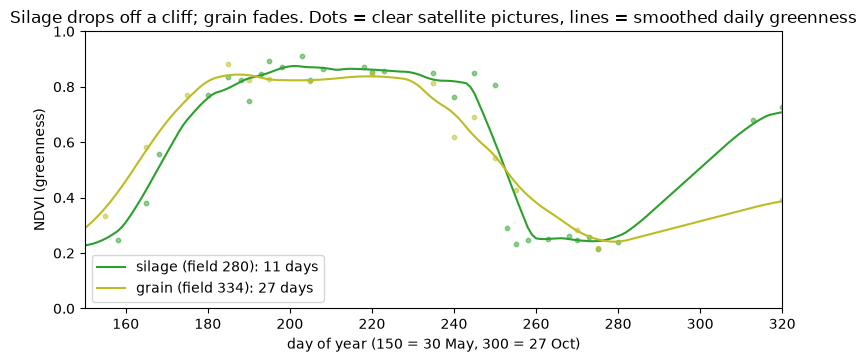

In [7]:
# What rule 1 sees: one silage and one grain field, Maryland 2021
fig, ax = plt.subplots(figsize=(9, 3.6))
for fid, colour, name in [("barc_280", "tab:green", "silage (field 280)"), ("barc_334", "tab:olive", "grain (field 334)")]:
    s = ndvi_md[(ndvi_md["field_id"] == fid) & (ndvi_md["year"] == 2021)]
    line = greenness_line(s)
    clear = s[s["valid_frac"] >= MIN_CLEAR]
    ax.plot(line.index, line.values, color=colour, label=f"{name}: {field_features(s)['drop_days']} days")
    ax.scatter(pd.to_datetime(clear["date"]).dt.day_of_year, clear["ndvi"], s=10, color=colour, alpha=0.5)
ax.set(xlim=(150, 320), ylim=(0, 1), xlabel="day of year (150 = 30 May, 300 = 27 Oct)", ylabel="NDVI (greenness)",
       title="Silage drops off a cliff; grain fades. Dots = clear satellite pictures, lines = smoothed daily greenness")
ax.legend(loc="lower left")
plt.show()

### Classify a new field

`classify_field` takes a field outline and a year. It downloads that field's Sentinel-2 pictures (free, Microsoft
Planetary Computer, no account; about a minute per field-season), finds the county, and applies both rules with the
cut-off learned in Quebec. Pass `ndvi=` to reuse a series you already have. The example below reuses a cached
Maryland series, so it runs offline.

The output says which rule decided. `winter_vegetation = False` means rule 2 was not allowed for that county.

In [8]:
def download_ndvi(geometry, crs, year, start="03-01", end="12-20", max_cloud=90):
    # NDVI series of one field from Sentinel-2 L2A: pixels fully inside the field (outline shrunk 10 m) that the
    # satellite's scene classification marks as vegetation or bare soil. One row per picture: date, valid_frac, ndvi.
    from concurrent.futures import ThreadPoolExecutor

    import planetary_computer
    import pystac_client
    import rasterio
    from rasterio.features import rasterize
    from rasterio.windows import from_bounds

    field = gpd.GeoSeries([geometry], crs=crs).to_crs(4326).iloc[0]
    catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                        modifier=planetary_computer.sign_inplace)
    items = catalog.search(collections=["sentinel-2-l2a"], intersects=field, datetime=f"{year}-{start}/{year}-{end}",
                           query={"eo:cloud_cover": {"lt": max_cloud}}).item_collection()

    def one(item):
        with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_TIMEOUT="60", GDAL_HTTP_MAX_RETRY="4"):
            bands = {}
            for name in ("B04", "B08", "SCL"):
                with rasterio.open(item.assets[name].href) as src:
                    if name == "B04":
                        shape = gpd.GeoSeries([field], crs=4326).to_crs(src.crs).buffer(-10).iloc[0]
                        if shape.is_empty:
                            return None
                        win = from_bounds(*shape.buffer(20).bounds, transform=src.transform).round_offsets().round_lengths()
                        transform, size = src.window_transform(win), (int(win.height), int(win.width))
                    w = from_bounds(*shape.buffer(20).bounds, transform=src.transform).round_offsets().round_lengths()
                    bands[name] = src.read(1, window=w, out_shape=size, boundless=True, fill_value=0).astype("float32")
        inside = rasterize([(shape, 1)], out_shape=size, transform=transform, fill=0).astype(bool)
        offset = 1000.0 if float(item.properties.get("s2:processing_baseline", "0")) >= 4.0 else 0.0
        red, nir = bands["B04"] - offset, bands["B08"] - offset
        clear = inside & np.isin(bands["SCL"], (4, 5)) & (bands["B04"] > 0)
        with np.errstate(divide="ignore", invalid="ignore"):
            ndvi = (nir - red) / (nir + red)
        values = ndvi[clear & np.isfinite(ndvi)]
        return {"date": item.datetime.date(), "valid_frac": clear.sum() / max(inside.sum(), 1),
                "ndvi": float(np.median(values)) if values.size else np.nan}

    with ThreadPoolExecutor(max_workers=8) as pool:
        rows = [r for r in pool.map(one, items) if r is not None]
    out = pd.DataFrame(rows).sort_values(["date", "valid_frac"]).drop_duplicates("date", keep="last")
    out["date"] = pd.to_datetime(out["date"])
    return out.reset_index(drop=True)


def classify_field(geometry, crs, year, ndvi=None, cutoff=x_quebec):
    series = download_ndvi(geometry, crs, year) if ndvi is None else ndvi
    row = pd.DataFrame({"field_id": ["new"], "year": [year]})
    row = pd.concat([row, region_of([geometry], crs)], axis=1)
    row = features(series.assign(field_id="new", year=year), row)
    row["call"], row["rule"] = predict(row, cutoff)
    row["call"] = row["call"].map({1: "silage", 0: "grain"})
    return row[["name", "state", "winter_vegetation", "drop_days", "winter_ndvi", "rule", "call"]]


# Example, offline: Maryland field 280 in 2021 (truly silage), reusing its cached series
field = barc[barc["OBJECTID"] == 280].geometry.iloc[0]
cached = ndvi_md[(ndvi_md["field_id"] == "barc_280") & (ndvi_md["year"] == 2021)]
classify_field(field, barc.crs, 2021, ndvi=cached)
# Online (downloads ~60 pictures):  classify_field(field, barc.crs, 2021)

,name,state,winter_vegetation,drop_days,winter_ndvi,rule,call
0,Prince George's County,MD,True,11,0.727005,1: fast drop,silage


## 2. Grain acres by state: model A-G9

**What it outputs:** acres of corn harvested for grain, for each of the ~41 states NASS publishes, plus their US sum,
as of 15 November. It uses no NASS data from the current year: the inputs are the acres farmers certified to USDA's
Farm Service Agency (FSA) this season, and NASS final acres of earlier years.

**How to read it:** the backtest table compares the model with *same as last year* on the same states. The 2026 table
is the forecast; NASS's own number for 2026 is published in January 2027.

In [9]:
FSA_FILES = pd.read_csv(DATA / "fsa" / "fsa_files.csv")                                  # one row per FSA release
FSA_STATE = pd.read_csv(DATA / "fsa" / "fsa_corn_state.csv", dtype={"state_fips": str})  # corn acres by state, use


def fsa_usable(asof, crop_year):
    # FSA releases a forecast made on `asof` may use: this season's releases published by then, plus history.
    ok = FSA_FILES[(FSA_FILES["status"] == "ok") & FSA_FILES["assumed_published"].notna()]
    published = pd.to_datetime(ok["assumed_published"]) <= pd.Timestamp(asof)
    this_season = (ok["crop_year"] == crop_year) & ~ok["vintage"].astype(str).str.startswith("final")
    return ok[published & (this_season | (ok["crop_year"] < crop_year))]


def fsa_grain_acres(release):
    # Planted acres with intended use "grain", by state, in one FSA release.
    if release is None:
        return pd.Series(dtype=float)
    rows = FSA_STATE[(FSA_STATE["crop_year"] == release["crop_year"])
                     & (FSA_STATE["data_as_of"] == release["data_as_of"]) & (FSA_STATE["intended_use"] == "grain")]
    return rows.groupby("state")["planted_acres"].sum()


def grain_a_g9(year, asof):
    usable = fsa_usable(asof, year)
    last = GRAIN_FINAL.loc[year - 1].dropna()            # fallback for any state without usable FSA data
    this_season = usable[usable["crop_year"] == year].sort_values("data_as_of")
    if this_season.empty:
        return last
    fsa_now = fsa_grain_acres(this_season.iloc[-1]).reindex(last.index)

    def final_release(y):
        r = usable[(usable["crop_year"] == y) & usable["vintage"].astype(str).str.startswith("final")]
        return None if r.empty else r.sort_values("data_as_of").iloc[-1]

    # Step 1: each state's usual ratio of NASS final acres to FSA-certified acres, median of the last 3 years
    ratios, history = [], []
    for k in (1, 2, 3):
        release = final_release(year - k)
        if release is None:
            continue
        nass_k, fsa_k = GRAIN_FINAL.loc[year - k].dropna(), fsa_grain_acres(release)
        ratios.append((nass_k / fsa_k.reindex(nass_k.index).where(lambda s: s > 0)).reindex(last.index))
        history.append((nass_k, fsa_k))
    ratio = pd.concat(ratios, axis=1).median(axis=1, skipna=True)
    ok = (fsa_now > 0) & ratio.between(0.25, 4.0)        # implausible ratio -> use last year's acres
    pred = pd.Series(np.where(ok, fsa_now * ratio, last), index=last.index)

    # Step 2: one national factor so the FSA states sum to (their FSA total x median national NASS/FSA ratio)
    states = ok[ok].index
    national = []
    for nass_k, fsa_k in history:
        n, f = nass_k.reindex(states), fsa_k.reindex(states)
        both = n.notna() & f.gt(0)
        if both.any():
            national.append(n[both].sum() / f[both].sum())
    if national:
        pred[states] *= fsa_now[states].sum() * np.median(national) / pred[states].sum()
    return pred


years = range(2012, 2026)
grain_pred = {t: grain_a_g9(t, date(t, 11, 15)) for t in years}
grain_scores = score(grain_pred, GRAIN_FINAL)
grain_base = score(same_as_last_year(GRAIN_FINAL, years), GRAIN_FINAL)
print("Grain backtest, forecast as of 15 November each year")
summary(grain_scores, grain_base)

Grain backtest, forecast as of 15 November each year


,model,same as last year
2017-2024 state error %,1.69,7.35
2017-2024 |US error| %,0.96,4.11
2025 US error %,-0.88,-8.69
2025 state error %,1.62,9.23


In [10]:
grain_2026 = grain_a_g9(2026, date(2026, 11, 15))
lo, hi = us_range(grain_2026.sum(), grain_scores)
print(f"2026 US corn for grain (A-G9, {grain_2026.notna().sum()} states): {grain_2026.sum() / 1e6:.2f}M acres, "
      f"rough 80% range {lo / 1e6:.2f}M to {hi / 1e6:.2f}M")
(grain_2026 / 1e3).round(0).sort_values(ascending=False).head(10).rename("2026 grain, thousand acres").to_frame()

2026 US corn for grain (A-G9, 42 states): 88.75M acres, rough 80% range 87.65M to 90.33M


,"2026 grain, thousand acres"
state,
IOWA,12788.0
ILLINOIS,10862.0
NEBRASKA,9619.0
MINNESOTA,8365.0
KANSAS,6533.0
SOUTH DAKOTA,5914.0
INDIANA,5119.0
NORTH DAKOTA,4501.0
MISSOURI,3474.0


## 3. Silage acres by state: model B-S6

**What it outputs:** acres of corn harvested for silage, for each state NASS publishes (48–49 states), plus their US sum,
as of 15 November. NASS publishes no in-season silage figure, so before January this is the only number available.

**How to read it:** `alpha` and `gamma` are the model's two knobs, re-chosen every year on earlier years only (see
README). A state's silage acres move 10–20% a year, much of it survey noise, so expect state errors near 13% from any
method; the US total is much more stable.

In [11]:
ALPHAS = np.round(np.arange(0.20, 0.95, 0.05), 2)    # smoothing weights tried
GAMMAS = np.round(np.arange(0.00, 0.21, 0.01), 2)    # share of exposed grain acres chopped, per unit of shortfall


def chopping_exposure():
    # max(0, yield shortfall - 10%) x last year's grain acres. Shortfall = 1 - NASS in-season yield forecast /
    # linear trend of the previous 10 final yields.
    years = sorted(set(YIELD_FINAL.index) | set(YIELD_NOV.index))
    trend = pd.DataFrame(np.nan, index=years, columns=YIELD_FINAL.columns)
    for y in years:
        past = YIELD_FINAL.loc[y - 10:y - 1]
        for s in YIELD_FINAL.columns:
            v = past[s].dropna()
            if len(v) >= 5:
                trend.loc[y, s] = np.polyval(np.polyfit(v.index, v.to_numpy(), 1), y)
    shortfall = (1 - YIELD_NOV.reindex(index=years, columns=trend.columns) / trend).fillna(0.0)
    grain_last_year = GRAIN_FINAL.shift(1).reindex(index=years, columns=trend.columns).fillna(0.0)
    return (shortfall - 0.10).clip(lower=0) * grain_last_year


def smoothed_level(log_acres, alpha):
    # Exponential smoothing of log acres; row t holds the level known at the end of year t-1.
    level, rows = None, {}
    for y, x in log_acres.iterrows():
        level = x if level is None else (alpha * x + (1 - alpha) * level).fillna(level).fillna(x)
        rows[y + 1] = level
    return pd.DataFrame(rows).T


def silage_forecasts(silage, exposure, alpha, gamma):
    chopped = gamma * exposure.reindex(index=silage.index, columns=silage.columns).fillna(0.0)
    normal = (silage - chopped).clip(lower=0.3 * silage)          # past acres without their own drought chopping
    base = np.exp(smoothed_level(np.log(normal), alpha))
    return base + gamma * exposure.reindex(index=base.index, columns=base.columns).fillna(0.0)


def mean_state_error(pred, actual, years):
    errors = []
    for t in years:
        p, a = pred.loc[t], actual.loc[t]
        ok = p.notna() & a.notna()
        errors.append((p[ok] - a[ok]).abs().sum() / a[ok].sum())
    return float(np.mean(errors))


EXPOSURE = chopping_exposure()


def silage_b_s6(year):
    silage = SILAGE_FINAL.loc[:year - 1]                          # only finals published before `year`
    past = range(2005, year)
    alpha = min(ALPHAS, key=lambda a: mean_state_error(np.exp(smoothed_level(np.log(silage), a)), silage, past))
    by_gamma = {g: silage_forecasts(silage, EXPOSURE, alpha, g) for g in GAMMAS}
    gamma = min(GAMMAS, key=lambda g: mean_state_error(by_gamma[g], silage, past))
    return by_gamma[gamma].loc[year].dropna(), alpha, gamma


silage_pred = {t: silage_b_s6(t)[0] for t in years}
silage_scores = score(silage_pred, SILAGE_FINAL)
silage_base = score(same_as_last_year(SILAGE_FINAL, years), SILAGE_FINAL)
print("Silage backtest, forecast as of 15 November each year")
summary(silage_scores, silage_base)

Silage backtest, forecast as of 15 November each year


,model,same as last year
2017-2024 state error %,12.81,14.53
2017-2024 |US error| %,3.36,4.08
2025 US error %,2.06,0.32
2025 state error %,13.14,13.96


In [12]:
silage_2026, alpha, gamma = silage_b_s6(2026)
lo, hi = us_range(silage_2026.sum(), silage_scores)
print(f"2026 US corn for silage (B-S6, {len(silage_2026)} states): {silage_2026.sum() / 1e6:.2f}M acres, "
      f"rough 80% range {lo / 1e6:.2f}M to {hi / 1e6:.2f}M   (alpha {alpha}, gamma {gamma})")
(silage_2026 / 1e3).round(0).sort_values(ascending=False).head(10).rename("2026 silage, thousand acres").to_frame()

2026 US corn for silage (B-S6, 49 states): 6.25M acres, rough 80% range 5.88M to 6.42M   (alpha 0.4, gamma 0.05)


,"2026 silage, thousand acres"
state,
WISCONSIN,830.0
NEW YORK,463.0
SOUTH DAKOTA,424.0
MINNESOTA,378.0
CALIFORNIA,366.0
MICHIGAN,333.0
PENNSYLVANIA,327.0
IOWA,305.0
KANSAS,275.0


## 4. The 2025 check, state by state

2025 is the year the organizers scored against (NASS Quick Stats, 2025 final acres). Each row: our 15-November-2025
forecast next to NASS's final. `error %` = (forecast − final) ÷ final for that state.

In [13]:
def compare_2025(pred, final, name):
    t = pd.DataFrame({"forecast": pred[2025], "NASS final": final.loc[2025]}).dropna()
    t["error %"] = 100 * (t["forecast"] / t["NASS final"] - 1)
    us = t[["forecast", "NASS final"]].sum()
    t.loc["US (sum)"] = [us["forecast"], us["NASS final"], 100 * (us["forecast"] / us["NASS final"] - 1)]
    t[["forecast", "NASS final"]] = (t[["forecast", "NASS final"]] / 1e3).round(0)
    return t.round(1).rename(columns={"forecast": f"{name} forecast (k acres)", "NASS final": "NASS final (k acres)"})


big = SILAGE_FINAL.loc[2025].sort_values(ascending=False).index[:10]
silage_2025 = compare_2025(silage_pred, SILAGE_FINAL, "silage")
silage_2025.loc[list(big) + ["US (sum)"]]

,silage forecast (k acres),NASS final (k acres),error %
state,,,
WISCONSIN,787.0,885.0,-11.1
NEW YORK,446.0,495.0,-9.8
SOUTH DAKOTA,450.0,390.0,15.3
CALIFORNIA,363.0,370.0,-1.8
MINNESOTA,389.0,360.0,8.0
MICHIGAN,327.0,340.0,-3.8
PENNSYLVANIA,333.0,315.0,5.7
IDAHO,247.0,280.0,-11.7
IOWA,350.0,250.0,40.1


In [14]:
grain_2025 = compare_2025(grain_pred, GRAIN_FINAL, "grain")
top = grain_2025.drop("US (sum)").sort_values("NASS final (k acres)", ascending=False).index[:10]
grain_2025.loc[list(top) + ["US (sum)"]]

,grain forecast (k acres),NASS final (k acres),error %
state,,,
IOWA,13063.0,13150.0,-0.7
ILLINOIS,11011.0,10950.0,0.6
NEBRASKA,10274.0,10390.0,-1.1
MINNESOTA,8394.0,8440.0,-0.5
KANSAS,6126.0,6450.0,-5.0
SOUTH DAKOTA,6118.0,6350.0,-3.7
INDIANA,5267.0,5240.0,0.5
NORTH DAKOTA,4386.0,4490.0,-2.3
MISSOURI,3632.0,3640.0,-0.2


## Limits

* **Acreage:** grain is ~98% right by state and ~99% for the US. Silage state errors stay near 13%, and most of that is
  noise in NASS's own state series. No method we tried got much below it.
* **Caveman rule:** 44 Maryland field-years is a small test. About a third of Quebec silage dries slowly before it is
  cut and gets called grain. Winter vegetation (rule 2) needs pictures through December.
* **Fields vs acres:** a 95%-accurate field rule does not make good state acres on its own. Where silage is only ~2% of
  corn (e.g. Iowa), even a few percent of false alarms outnumber the real silage fields. That is why the acreage
  numbers come from models 1 and 2.